# Ключевые статьи в оптимизации с локальными шагами

Бадерко Макар Александрович, Б05-621

В этом ноутбуке я собираю данные, отбираю статьи, считаю показатели и строю граф.
Используются сохранённые ответы OpenAlex от 10.11.2026. Для повторного сбора есть отдельный блок с API.

Для запуска нужны Python 3.11 и библиотеки из `requirements_notebook.txt`.
Все ячейки можно выполнить по порядку; результаты появятся в папке `notebook_results`.

In [1]:
import csv
import gzip
import hashlib
import html
import json
import math
import os
import re
import statistics
import time
import unicodedata
from collections import Counter, defaultdict
from datetime import datetime, timezone
from html import escape
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import Request, urlopen
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import resvg_py
from IPython.display import Image, display

project_dir = Path.cwd()
results_dir = project_dir / "notebook_results"
results_dir.mkdir(exist_ok=True)
plt.rcParams.update(
    {"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False}
)

## 1. Данные OpenAlex

Для результатов отчёта использую сохранённые ответы из `data`.
Если нужен новый сбор, можно поставить `REFRESH_API = True`. Новые ответы сохраняются отдельно и не подменяют данные отчёта.
Ключ API при наличии берётся из переменной окружения `OPENALEX_API_KEY`.

In [2]:
REFRESH_API = False
API_KEY = os.environ.get("OPENALEX_API_KEY", "")
API_BASE = "https://api.openalex.org"
API_FIELDS = ",".join(
    [
        "id",
        "doi",
        "display_name",
        "publication_year",
        "publication_date",
        "authorships",
        "referenced_works",
        "cited_by_count",
        "type",
        "primary_location",
        "locations",
    ]
)
saved_search = json.load(
    gzip.open(project_dir / "data/original.json.gz", "rt", encoding="utf8")
)
queries = [term for term, count in saved_search["queries"]]
publication_period = saved_search["period"]
api_log = []
api_dir = (
    results_dir
    / "api_collection"
    / datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
    if REFRESH_API
    else None
)

In [3]:
def openalex_get(path, params=None, cache_dir=None):
    url = API_BASE + "/" + path.lstrip("/")
    if params:
        url += "?" + urlencode(params)
    cache_path = None
    if cache_dir is not None:
        cache_dir.mkdir(parents=True, exist_ok=True)
        cache_path = cache_dir / (hashlib.sha256(url.encode()).hexdigest() + ".json")
        if cache_path.exists():
            api_log.append({"url": url, "status": 200, "cached": True})
            return json.loads(cache_path.read_text(encoding="utf8"))["response"]
    headers = {"User-Agent": "LocalSGDLiteratureProject/1.0"}
    if API_KEY:
        headers["Authorization"] = "Bearer " + API_KEY
    for attempt in range(5):
        try:
            with urlopen(Request(url, headers=headers), timeout=60) as response:
                payload = json.load(response)
            stamp = datetime.now(timezone.utc).isoformat()
            api_log.append(
                {"url": url, "status": 200, "cached": False, "collected_utc": stamp}
            )
            if cache_path is not None:
                cache_path.write_text(
                    json.dumps(
                        {"url": url, "collected_utc": stamp, "response": payload},
                        ensure_ascii=False,
                    ),
                    encoding="utf8",
                )
            time.sleep(0.15)
            return payload
        except HTTPError as error:
            api_log.append({"url": url, "status": error.code, "cached": False})
            if error.code not in {429, 500, 502, 503, 504} or attempt == 4:
                raise
            delay = error.headers.get("Retry-After", "")
            delay = (
                float(delay)
                if delay.replace(".", "", 1).isdigit()
                else 2 ** (attempt + 1)
            )
            if delay > 60:
                raise RuntimeError("Лимит OpenAlex: повторите сбор позже.") from None
            time.sleep(max(delay, 1))
        except URLError:
            if attempt == 4:
                raise
            time.sleep(2 ** (attempt + 1))

In [4]:
def collect_title_queries(terms, period, save_dir):
    records, query_counts = ({}, [])
    for term in terms:
        seen = 0
        for page in range(1, 101):
            params = {
                "filter": f"title.search:{term},from_publication_date:{period[0]},to_publication_date:{period[1]}",
                "per_page": 100,
                "page": page,
                "select": API_FIELDS,
            }
            reply = openalex_get("works", params, save_dir / "requests")
            total = reply["meta"]["count"]
            if total > 10000:
                raise RuntimeError(
                    "Больше 10 000 результатов: разделите период поиска по годам."
                )
            batch = reply["results"]
            for work in batch:
                entry = records.setdefault(work["id"], {"work": work, "queries": []})
                if term not in entry["queries"]:
                    entry["queries"].append(term)
            seen += len(batch)
            if seen >= total:
                break
            if not batch:
                raise RuntimeError("API вернул пустую страницу до конца выдачи.")
        query_counts.append([term, seen])
    snapshot = {
        "collected_utc": datetime.now(timezone.utc).isoformat(),
        "period": period,
        "queries": query_counts,
        "data": list(records.values()),
    }
    with gzip.open(save_dir / "original.json.gz", "wt", encoding="utf8") as output:
        json.dump(snapshot, output, ensure_ascii=False)
    return snapshot


if REFRESH_API:
    api_dir.mkdir(parents=True, exist_ok=True)
    search_results = collect_title_queries(queries, publication_period, api_dir)
else:
    search_results = saved_search
display(pd.DataFrame(search_results["queries"], columns=["Запрос", "Получено записей"]))
print("Уникальных записей:", len(search_results["data"]))

,Запрос,Получено записей
0,local sgd,87
1,local stochastic gradient descent,20
2,federated averaging,170
3,federated optimization,1802
4,federated optimisation,31
5,fedavg,72
6,diloco,7
7,adloco,0
8,controlled averaging for federated learning,4
9,communication-efficient learning of deep netwo...,1


Уникальных записей: 2200


In [5]:
baseline_rows = list(
    csv.DictReader(
        (project_dir / "data/baseline_rankings.csv").open(encoding="utf-8-sig")
    )
)
search_by_id = {
    row["work"]["id"].split("/")[-1]: row["work"] for row in saved_search["data"]
}
baseline_ids = {i for row in baseline_rows for i in row["variants"].split("|")}
reference_counts = Counter()
for row in baseline_rows:
    references = {
        v.split("/")[-1]
        for i in row["variants"].split("|")
        for v in search_by_id[i]["referenced_works"]
    }
    reference_counts.update(references)
candidate_counts = {
    i: reference_counts[i]
    for i in sorted(reference_counts)
    if reference_counts[i] >= 3 and i not in baseline_ids
}
print("Внешних ID для проверки:", len(candidate_counts))


def collect_id_batches(ids, save_dir):
    replies = []
    for start in range(0, len(ids), 100):
        batch = ids[start : start + 100]
        params = {
            "filter": "openalex:" + "|".join(batch),
            "per_page": 100,
            "select": API_FIELDS,
        }
        reply = openalex_get("works", params, save_dir / "requests")
        item = {
            "url": API_BASE + "/works?" + urlencode(params),
            "requested": batch,
            "response": reply,
        }
        (save_dir / f"audit_{start // 100 + 1}.json").write_text(
            json.dumps(item, ensure_ascii=False), encoding="utf8"
        )
        replies.append(item)
    return replies


if REFRESH_API:
    need = sorted(i for i in candidate_counts if i not in search_by_id)
    neighbor_batches = collect_id_batches(need, api_dir)
else:
    neighbor_batches = [
        json.loads(p.read_text())
        for p in sorted((project_dir / "data").glob("audit_[1-4].json"))
    ]
display(
    pd.DataFrame(
        [
            {
                "Пакет": j + 1,
                "Запрошено": len(p["requested"]),
                "Получено": len(p["response"]["results"]),
            }
            for j, p in enumerate(neighbor_batches)
        ]
    )
)

Внешних ID для проверки: 409


,Пакет,Запрошено,Получено
0,1,100,100
1,2,100,100
2,3,100,92
3,4,92,81


In [6]:
def resolve_work_ids(ids, save_dir):
    resolved = {}
    for ident in ids:
        try:
            work = openalex_get(
                "works/" + ident, {"select": API_FIELDS}, save_dir / "requests"
            )
            resolved[ident] = {"work": work, "resolved_to": work["id"].split("/")[-1]}
        except HTTPError as error:
            if error.code not in {404, 410}:
                raise
            resolved[ident] = {"error": f"HTTP {error.code}"}
    (save_dir / "resolved.json").write_text(
        json.dumps(resolved, ensure_ascii=False), encoding="utf8"
    )
    return resolved


saved_direct = json.loads((project_dir / "data/direct_lookups.json").read_text())
if REFRESH_API:
    known_ids = set(search_by_id) | {
        w["id"].split("/")[-1]
        for batch in neighbor_batches
        for w in batch["response"]["results"]
    }
    resolved_ids = resolve_work_ids(sorted(set(candidate_counts) - known_ids), api_dir)
    extra_papers = {}
    for name, saved in saved_direct.items():
        path = saved["url"].removeprefix(API_BASE + "/")
        extra_papers[name] = {
            "url": saved["url"],
            "work": openalex_get(path, {"select": API_FIELDS}, api_dir / "requests"),
        }
    (api_dir / "direct_lookups.json").write_text(
        json.dumps(extra_papers, ensure_ascii=False), encoding="utf8"
    )
    for name, term in {
        "fednova": "Tackling the Objective Inconsistency Problem in Heterogeneous Federated Optimization",
        "adloco": "AdLoCo",
    }.items():
        params = {
            "filter": f'title.search:"{term}",from_publication_date:{publication_period[0]},to_publication_date:{publication_period[1]}',
            "per_page": 100,
            "select": API_FIELDS,
        }
        item = {
            "url": API_BASE + "/works?" + urlencode(params),
            "response": openalex_get("works", params, api_dir / "requests"),
        }
        (api_dir / f"{name}.json").write_text(
            json.dumps(item, ensure_ascii=False), encoding="utf8"
        )
    (api_dir / "audit_candidates.json").write_text(
        json.dumps({"minimum_sources": 3, "candidates": candidate_counts}),
        encoding="utf8",
    )
    (api_dir / "request_log.json").write_text(
        json.dumps(api_log, ensure_ascii=False, indent=2), encoding="utf8"
    )
else:
    resolved_ids = json.loads((project_dir / "data/resolved.json").read_text())
    extra_papers = saved_direct
display(
    pd.DataFrame(
        [
            {
                "Проверка": name,
                "Запрошено": item["url"],
                "Полученный ID": item["work"]["id"],
            }
            for name, item in extra_papers.items()
        ]
    )
)
print("ID восстановлено:", sum("work" in item for item in resolved_ids.values()))
print("ID не разрешено:", sum("error" in item for item in resolved_ids.values()))

,Проверка,Запрошено,Полученный ID
0,fednova_id,https://api.openalex.org/works/W3043723611,https://openalex.org/W3194243671
1,fednova_doi,https://api.openalex.org/works/https://doi.org...,https://openalex.org/W3194243671
2,adloco_doi,https://api.openalex.org/works/https://doi.org...,https://openalex.org/W7077910239


ID восстановлено: 3
ID не разрешено: 16


## 2. Отбор статей и объединение версий

В исходный набор входят статьи, найденные по названиям методов. Затем добавляю работы, на которые ссылаются хотя бы три исходные статьи, если их названия соответствуют теме.
Препринт и опубликованную версию объединяю по DOI, arXiv ID или названию с общими авторами.
Обзоры для внешней проверки исключаю из ранжирования.

In [7]:
TERMS = [
    "local sgd",
    "local stochastic gradient descent",
    "federated averaging",
    "federated optimization",
    "federated optimisation",
    "fedavg",
    "diloco",
    "adloco",
    "controlled averaging for federated learning",
    "communication-efficient learning of deep networks from decentralized data",
    "low-communication training",
]
HOLDOUT = [
    "A Field Guide to Federated Optimization",
    "Federated Learning on Non-IID Data Silos: An Experimental Study",
    "Towards Efficient Communications in Federated Learning: A Contemporary Survey",
    "Non-IID data in Federated Learning: A Survey with Taxonomy, Metrics, Methods, Frameworks and Future Directions",
]
EXCLUDED = {"W2996136858": "hydrology acronym", "W4386768963": "code/data repository"}
METHOD = re.compile(
    "optim|gradient|sgd|averag|regulariz|converg|momentum|local.?update|client.?drift",
    re.I,
)
DOMAIN = re.compile("local|federat|decentral", re.I)
TYPES = {
    "article",
    "preprint",
    "review",
    "book-chapter",
    "proceedings-article",
    "conference-paper",
}
ORIGINAL_TITLES = {
    "2007.07481": "Tackling the Objective Inconsistency Problem in Heterogeneous Federated Optimization"
}
DATE_OVERRIDES = {"2007.07481": "2020-07-15"}
KEYS = {
    "1602.05629": "FedAvg",
    "1805.09767": "Local SGD",
    "1812.06127": "FedProx",
    "1910.06378": "SCAFFOLD",
}
REVIEW_TITLE = re.compile(
    "\\bsurvey\\b|\\breview\\b|field guide|advances and open problems", re.I
)

In [8]:
def normalize_text(s):
    s = html.unescape(re.sub("<[^>]*>", " ", s or ""))
    s = "".join(
        x for x in unicodedata.normalize("NFKD", s) if not unicodedata.combining(x)
    )
    return " ".join(re.findall("[a-z0-9]+", s.lower()))


def title_key(s):
    return normalize_text(s).replace(" ", "")


def arxiv_ids(w):
    urls = [w.get("doi") or ""]
    for loc in [w.get("primary_location")] + (w.get("locations") or []):
        if loc:
            urls.extend([loc.get("landing_page_url") or "", loc.get("pdf_url") or ""])
    found = set()
    for u in urls:
        found.update(
            re.findall("arxiv(?:\\.org/(?:abs|pdf)/|\\.)(\\d{4}\\.\\d{4,5})", u, re.I)
        )
    for u in urls:
        found.update(
            a + "." + b for a, b in re.findall("abs-(\\d{4})-(\\d{4,5})", u, re.I)
        )
    return found


def get_author_ids(w):
    return {
        a["author"]["id"] for a in w.get("authorships", []) if a["author"].get("id")
    }


def save_table(name, rows):
    if not rows:
        return
    with (results_dir / name).open("w", encoding="utf-8-sig", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

In [9]:
raw = json.load(gzip.open(project_dir / "data/original.json.gz", "rt", encoding="utf8"))
records = {r["work"]["id"].split("/")[-1]: r["work"] for r in raw["data"]}
for p in sorted((project_dir / "data").glob("audit_[1-4].json")):
    for w in json.loads(p.read_text())["response"]["results"]:
        records[w["id"].split("/")[-1]] = w
for name in ["fednova", "adloco"]:
    path = project_dir / "data" / (name + ".json")
    if path.exists():
        for w in json.loads(path.read_text())["response"]["results"]:
            records[w["id"].split("/")[-1]] = w
direct = json.loads((project_dir / "data/direct_lookups.json").read_text())
redirects = {}
for result in direct.values():
    if "work" not in result:
        continue
    w = result["work"]
    records[w["id"].split("/")[-1]] = w
    requested = result["url"].split("/")[-1]
    if requested.startswith("W"):
        redirects[requested] = w["id"].split("/")[-1]
for alias, r in json.loads((project_dir / "data/resolved.json").read_text()).items():
    if "work" in r:
        ident = r["resolved_to"]
        records[ident] = r["work"]
        redirects[alias] = ident
source_counts = json.loads((project_dir / "data/audit_candidates.json").read_text())[
    "candidates"
]
with (project_dir / "data/baseline_rankings.csv").open(encoding="utf-8-sig") as f:
    baseline = list(csv.DictReader(f))
initial_ids = {i for p in baseline for i in p["variants"].split("|")}

In [10]:
version_parent = {i: i for i in records}


def find_version(i):
    while version_parent[i] != i:
        version_parent[i] = version_parent[version_parent[i]]
        i = version_parent[i]
    return i


def merge_versions(a, b):
    a, b = (find_version(a), find_version(b))
    if a != b:
        version_parent[max(a, b)] = min(a, b)


for p in baseline:
    ids = p["variants"].split("|")
    for i in ids[1:]:
        merge_versions(ids[0], i)
doi_index = {}
arxiv_index = {}
title_index = defaultdict(list)
for ident, w in sorted(records.items()):
    doi = (w.get("doi") or "").lower().replace("https://doi.org/", "")
    if doi:
        if doi in doi_index:
            merge_versions(ident, doi_index[doi])
        doi_index[doi] = ident
    for aid in arxiv_ids(w):
        if aid in arxiv_index:
            merge_versions(ident, arxiv_index[aid])
        arxiv_index[aid] = ident
    key = title_key(w["display_name"])
    if key:
        for other in title_index[key]:
            if get_author_ids(w) & get_author_ids(records[other]):
                merge_versions(ident, other)
        title_index[key].append(ident)

In [11]:
def canonical_paper(group, admission):
    representative = min(group, key=lambda work: (-work["cited_by_count"], work["id"]))
    paper_id = representative["id"].split("/")[-1]
    version_ids = {work["id"].split("/")[-1] for work in group}
    arxiv = set().union(*(arxiv_ids(work) for work in group))
    author_ids = set().union(*(get_author_ids(work) for work in group))
    references = {
        ref.split("/")[-1] for work in group for ref in work.get("referenced_works", [])
    }
    title = next(
        (ORIGINAL_TITLES[a] for a in arxiv if a in ORIGINAL_TITLES),
        representative["display_name"],
    )
    dates = [work["publication_date"] for work in group]
    dates += [DATE_OVERRIDES[a] for a in arxiv if a in DATE_OVERRIDES]
    key = next((KEYS[a] for a in KEYS if a in arxiv), "")
    is_review = any(
        work["type"] == "review" or REVIEW_TITLE.search(work["display_name"])
        for work in group
    )
    paper = dict(
        id=paper_id,
        title=title,
        authors=", ".join(
            item["author"]["display_name"]
            for item in representative.get("authorships", [])
        ),
        date=min(dates),
        G=max(work["cited_by_count"] for work in group),
        key=key,
        admission=admission,
        variants="|".join(sorted(version_ids)),
        arxiv="|".join(sorted(arxiv)),
        url=representative.get("doi") or representative["id"],
        review=int(is_review),
    )
    return (paper, references, author_ids)

In [12]:
groups = defaultdict(list)
for ident, w in records.items():
    groups[find_version(ident)].append(w)
papers = {}
aliases = {}
paper_references = {}
author_sets = {}
audit = []
for group in groups.values():
    ids = {w["id"].split("/")[-1] for w in group}
    titles = [w["display_name"] for w in group]
    group_arxiv = set().union(*(arxiv_ids(w) for w in group))
    titles.extend(ORIGINAL_TITLES[a] for a in group_arxiv if a in ORIGINAL_TITLES)
    is_holdout = any(title_key(t) in {title_key(x) for x in HOLDOUT} for t in titles)
    valid_metadata = any(
        w["type"] in TYPES and "2010-01-01" <= w["publication_date"] <= "2025-12-31"
        for w in group
    )
    is_initial = bool(ids & initial_ids) or any(
        any(title_key(term) in title_key(t) for term in TERMS) for t in titles
    )
    source_count = max(
        [source_counts.get(i, 0) for i in ids]
        + [
            source_counts.get(alias, 0)
            for alias, target in redirects.items()
            if target in ids
        ]
        + [0]
    )
    matches_topic = any(DOMAIN.search(t) and METHOD.search(t) for t in titles)
    include = (
        valid_metadata
        and (not is_holdout)
        and (not ids & set(EXCLUDED))
        and (is_initial or (source_count >= 3 and matches_topic))
    )
    if is_holdout:
        reason = "holdout"
    elif include and is_initial:
        reason = "baseline"
    elif include:
        reason = "snowball"
    else:
        reason = "outside_rule"
    for w in group:
        audit.append(
            dict(
                id=w["id"].split("/")[-1],
                title=w["display_name"],
                include=int(include),
                reason=reason,
                baseline_sources=source_count,
            )
        )
    if not include:
        continue
    paper, references, author_ids = canonical_paper(group, reason)
    paper_id = paper["id"]
    papers[paper_id] = paper
    paper_references[paper_id] = references
    author_sets[paper_id] = author_ids
    for version_id in ids:
        aliases[version_id] = paper_id

In [13]:
pd.Series(
    {
        "Исходные статьи": sum(p["admission"] == "baseline" for p in papers.values()),
        "Добавлено при расширении": sum(
            p["admission"] == "snowball" for p in papers.values()
        ),
        "Всего статей": len(papers),
    }
)

Исходные статьи             294
Добавлено при расширении     43
Всего статей                337
dtype: int64

## 3. Ссылки и ранжирование

К ссылкам OpenAlex добавляю связи из `accepted_edges.csv`: это ссылки, уже найденные в библиографиях PDF.
Затем считаю обычную цитируемость, PageRank и дробный подсчёт. В $S$ ссылка с общими авторами даёт нулевой вклад, но остаётся в знаменателе.

In [14]:
def citation_scores(paper_ids, edges, include_edge=None):
    counts = Counter(v for u, v in edges if include_edge is None or include_edge(u, v))
    return {i: counts[i] for i in paper_ids}


def global_citation_scores(papers):
    return {i: int(p["G"]) for i, p in papers.items()}


def pagerank_scores(graph, alpha=0.85):
    return nx.pagerank(graph, alpha=alpha, tol=1e-12, max_iter=2000)


def fractional_citation_scores(graph, author_sets):
    fractional, support, votes = (Counter(), Counter(), [])
    for u, v in sorted(graph.edges()):
        k = graph.out_degree(u)
        # Ссылки с общими авторами остаются в знаменателе.
        shared = bool(author_sets[u] & author_sets[v])
        weight = 0.0 if shared else 1 / k
        fractional[v] += 1 / k
        support[v] += weight
        votes.append(
            dict(
                citing=u,
                cited=v,
                k_u=k,
                shared_author=int(shared),
                a_uv=int(not shared),
                weight=weight,
                weight_fractional=1 / k,
            )
        )
    assert (
        abs(sum(fractional.values()) - sum(graph.out_degree(i) > 0 for i in graph))
        < 1e-09
    )
    return (fractional, support, votes)


def rank(scores, decimals=None):
    values = {
        i: round(s, decimals) if decimals is not None else s for i, s in scores.items()
    }
    return {
        i: 1 + sum(other > score for other in values.values())
        for i, score in values.items()
    }


def add_ranking_columns(papers, metrics):
    result = {i: dict(p) for i, p in papers.items()}
    for name, scores in metrics.items():
        ranked = rank(scores, decimals=10 if name in {"PR", "S", "F"} else None)
        for i in result:
            result[i][name] = scores.get(i, "")
            result[i][name + "_rank"] = ranked.get(i, "")
    return result

In [15]:
for alias, target in redirects.items():
    if target in aliases:
        aliases[alias] = aliases[target]
edges = {
    (u, aliases[v])
    for u, refs in paper_references.items()
    for v in refs
    if v in aliases
    and u != aliases[v]
    and (papers[u]["date"] > papers[aliases[v]]["date"])
}
openalex_edges = set(edges)
recovery_path = project_dir / "data/reference_recovery/accepted_edges.csv"
recovered = set()
recovery_evidence = Counter()
if recovery_path.exists():
    with recovery_path.open(encoding="utf-8-sig") as f:
        for e in csv.DictReader(f):
            u, v = (e["citing"], e["cited"])
            recovered.add((u, v))
            recovery_evidence[u, v] += 1
    edges |= recovered

In [16]:
counts = citation_scores(papers, edges)
independent = citation_scores(
    papers, edges, lambda u, v: not author_sets[u] & author_sets[v]
)
strict = citation_scores(
    papers, edges, lambda u, v: papers[u]["date"][:4] > papers[v]["date"][:4]
)
no_reviews = citation_scores(papers, edges, lambda u, v: not papers[u]["review"])
age = citation_scores(
    papers,
    edges,
    lambda u, v: 1 <= int(papers[u]["date"][:4]) - int(papers[v]["date"][:4]) <= 3,
)
base = citation_scores(papers, edges, lambda u, v: papers[u]["admission"] == "baseline")
graph = nx.DiGraph()
graph.add_nodes_from(sorted(papers))
graph.add_edges_from(sorted(edges))
fractional, support, votes = fractional_citation_scores(graph, author_sets)
save_table("metric_votes.csv", votes)
metrics = {
    "G": global_citation_scores(papers),
    "L": counts,
    "L_independent": independent,
    "PR": pagerank_scores(graph),
    "S": {i: support[i] for i in papers},
    "F": {i: fractional[i] for i in papers},
    "strict_year": {i: strict[i] for i in papers},
    "no_reviews": {i: no_reviews[i] for i in papers},
    "base_sources": {i: base[i] for i in papers},
    "age3": {i: age[i] for i, p in papers.items() if p["date"][:4] <= "2022"},
}
papers = add_ranking_columns(papers, metrics)

In [17]:
rows = sorted(papers.values(), key=lambda p: (p["L_rank"], p["G_rank"], p["id"]))
save_table("rankings.csv", rows)
save_table(
    "rankings_S.csv", sorted(rows, key=lambda p: (p["S_rank"], p["L_rank"], p["id"]))
)
save_table(
    "edges.csv",
    [
        dict(
            citing=u,
            cited=v,
            shared_author=int(bool(author_sets[u] & author_sets[v])),
            sources="|".join(
                name
                for name, present in [
                    ("openalex", (u, v) in openalex_edges),
                    ("pdf_bibliography", (u, v) in recovered),
                ]
                if present
            ),
            bibliography_evidence=recovery_evidence[u, v],
        )
        for u, v in sorted(edges)
    ],
)
save_table("selection_audit.csv", audit)
merged = [
    dict(id=i, variants=p["variants"], title=p["title"])
    for i, p in papers.items()
    if "|" in p["variants"]
]
save_table("merged_versions.csv", merged)

In [18]:
pd.Series(
    {
        "Статей": len(papers),
        "Связей OpenAlex": len(openalex_edges),
        "Добавлено из PDF": len(recovered - openalex_edges),
        "Всего связей": len(edges),
    }
)

Статей               337
Связей OpenAlex     1209
Добавлено из PDF     494
Всего связей        1703
dtype: int64

In [19]:
df = pd.DataFrame(rows)
top = df.sort_values(["S_rank", "L_rank", "id"]).head(10)
display(
    top[["title", "L", "S", "G", "L_rank", "S_rank", "PR_rank", "G_rank"]].round(
        {"S": 3}
    )
)

,title,L,S,G,L_rank,S_rank,PR_rank,G_rank
0,Communication-Efficient Learning of Deep Netwo...,207,52.903,15697,1,1,1,1
2,Federated Optimization in Heterogeneous Networks,107,16.974,4618,3,2,3,2
1,Local SGD Converges Fast and Communicates Little,110,16.638,925,2,3,2,12
3,SCAFFOLD: Stochastic Controlled Averaging for ...,106,11.780,1956,4,4,7,5
4,On the Convergence of FedAvg on Non-IID Data,84,11.247,2177,5,5,6,4
5,Adaptive Federated Optimization,61,8.516,1510,6,6,9,6
12,Federated Optimization: Distributed Machine Le...,31,6.156,2428,13,7,8,3
7,"Don't Use Large Mini-Batches, Use Local SGD",53,5.975,324,8,8,4,28
10,Tackling the Objective Inconsistency Problem i...,39,4.766,1166,11,9,16,9
49,Decentralized Federated Averaging,6,4.700,436,50,10,21,23


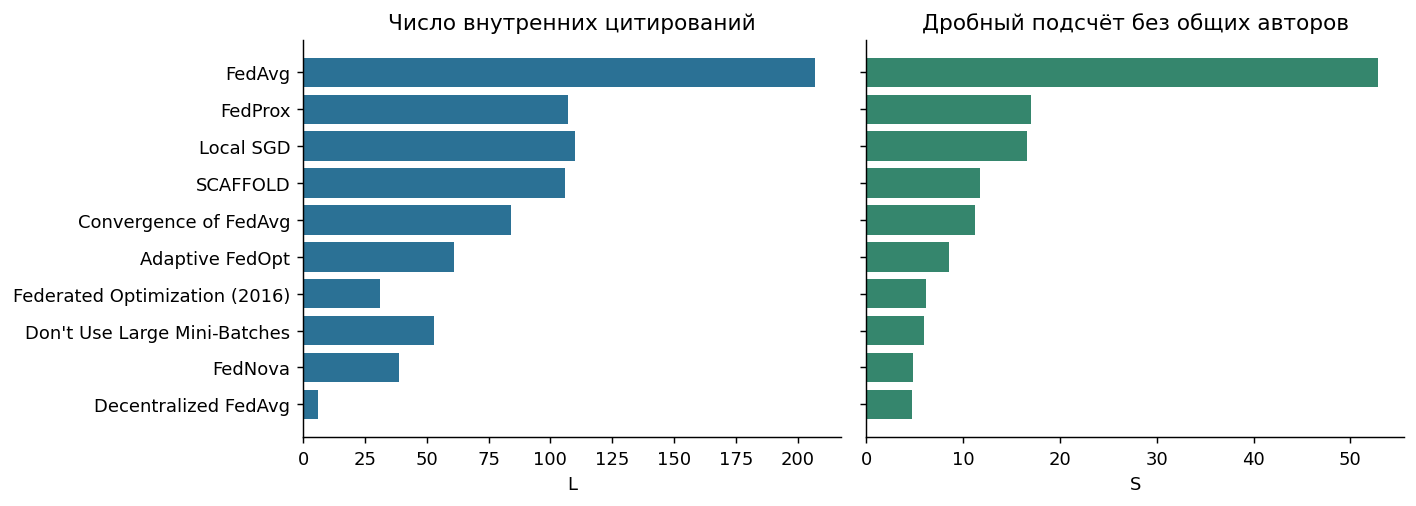

In [20]:
shown = top.iloc[::-1]
short_titles = {
    "On the Convergence of FedAvg on Non-IID Data": "Convergence of FedAvg",
    "Adaptive Federated Optimization": "Adaptive FedOpt",
    "Federated Optimization: Distributed Machine Learning for On-Device Intelligence": "Federated Optimization (2016)",
    "Don't Use Large Mini-Batches, Use Local SGD": "Don't Use Large Mini-Batches",
    "Tackling the Objective Inconsistency Problem in Heterogeneous Federated Optimization": "FedNova",
    "Decentralized Federated Averaging": "Decentralized FedAvg",
}
labels = [
    r["key"] or short_titles.get(r["title"], r["title"])
    for r in shown.to_dict("records")
]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, metric, color in zip(axes, ["L", "S"], ["#2b7195", "#35866d"]):
    ax.barh(labels, shown[metric], color=color)
    ax.set_xlabel(metric)
axes[0].set_title("Число внутренних цитирований")
axes[1].set_title("Дробный подсчёт без общих авторов")
fig.tight_layout()
fig.savefig(results_dir / "rankings.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Граф цитирований

На рисунке оставляю основную компоненту. Цвет показывает сообщество Louvain, размер вершины – число внутренних цитирований.
Часть стрелок убираю транзитивным сокращением. Показатели при этом считаются по полному графу.

In [21]:
citation_graph = nx.DiGraph()
citation_graph.add_nodes_from(sorted(papers))
citation_graph.add_edges_from(sorted(edges))
components = sorted(
    nx.weakly_connected_components(citation_graph),
    key=lambda ids: (-len(ids), min(ids)),
)
main_graph = nx.Graph()
main_graph.add_nodes_from(sorted(components[0]))
main_graph.add_edges_from((u, v) for u, v in sorted(edges) if u in components[0])
priority = {
    paper["id"]: rank
    for rank, key in enumerate(["FedAvg", "Local SGD", "FedProx", "SCAFFOLD"])
    for paper in rows
    if paper["key"] == key
}
communities = sorted(
    nx.community.louvain_communities(main_graph, seed=42),
    key=lambda ids: (
        min((priority.get(i, 99) for i in ids), default=99),
        -len(ids),
        min(ids),
    ),
)
community_by_id = {i: group for group, ids in enumerate(communities) for i in ids}
nodes = []
for paper in rows:
    i = paper["id"]
    nodes.append(
        dict(
            id=i,
            title=paper["title"],
            authors=paper["authors"],
            year=int(paper["date"][:4]),
            group=community_by_id.get(i, -1),
            key=paper["key"],
            L=int(paper["L"]),
            S=float(paper["S"]),
            S_rank=int(paper["S_rank"]),
            out=citation_graph.out_degree(i),
            G=int(paper["G"]),
            pr=int(paper["PR_rank"]),
            url=paper["url"],
            admission=paper["admission"],
        )
    )
network_data = dict(
    nodes=nodes,
    edges=sorted(citation_graph.edges()),
    cluster_sizes=list(map(len, communities)),
    leaders=[
        max(sorted(ids), key=lambda i: citation_graph.in_degree(i))
        for ids in communities
    ],
    components=list(map(len, components)),
)
(results_dir / "network.json").write_text(
    json.dumps(network_data, ensure_ascii=False), encoding="utf8"
)
corpus_nodes = len(citation_graph)
corpus_edges = citation_graph.number_of_edges()
visible_graph = citation_graph.subgraph(components[0]).copy()
graph_nodes = {node["id"]: node for node in nodes if node["id"] in visible_graph}
display_graph = nx.transitive_reduction(visible_graph)
component_edge_count = visible_graph.number_of_edges()
display_edge_count = display_graph.number_of_edges()
hidden_edges = component_edge_count - display_edge_count
group_count = len(communities)
print(
    f"На карте {len(graph_nodes)} статей и {display_edge_count} связей из {component_edge_count}."
)

На карте 276 статей и 520 связей из 1700.


In [22]:
width, height = (1800, 1195)
COLORS = [
    "#2b7195",
    "#8060a2",
    "#35866d",
    "#c27645",
    "#a1862e",
    "#437d89",
    "#af6586",
    "#536988",
    "#94714e",
]
# Положение групп выбираю для читаемости карты.
community_bounds = [
    (660, 385, 194, 140),
    (1110, 405, 189, 140),
    (390, 755, 153, 124),
    (970, 785, 159, 124),
    (1440, 655, 150, 120),
    (670, 1015, 142, 108),
    (1400, 1015, 145, 108),
    (235, 1065, 132, 102),
    (225, 360, 122, 102),
]
paper_labels = {
    "W2541884796": "FedAvg",
    "W2803867449": "Local SGD · Stich",
    "W2914328083": "FedProx",
    "W3006555759": "SCAFFOLD",
    "W2955213239": "Сходимость FedAvg",
    "W3194243671": "FedNova",
    "W7077910239": "AdLoCo",
}

In [23]:
def layout_community(subgraph, leader, radii, bounds):
    cx, cy, rx, ry = bounds
    ids = sorted(subgraph)
    local_graph = nx.Graph()
    local_graph.add_nodes_from(ids)
    local_graph.add_edges_from(sorted(subgraph.edges()))
    local = nx.kamada_kawai_layout(local_graph, scale=1)
    local = {i: np.array(local[i], dtype=float) for i in ids}
    center = local[leader].copy()
    for i in ids:
        local[i] -= center
    scale = max(
        max(abs(local[i][0]) / (rx - 22), abs(local[i][1]) / (ry - 22)) for i in ids
    )
    for i in ids:
        local[i] /= scale
    for _ in range(220):
        for j, u in enumerate(ids):
            for v in ids[:j]:
                delta = local[u] - local[v]
                distance = float(np.linalg.norm(delta))
                minimum = radii[u] + radii[v] + 5
                if distance < minimum:
                    if distance < 1e-06:
                        delta = np.array([1.0, 0.3])
                        distance = float(np.linalg.norm(delta))
                    shift = delta / distance * (minimum - distance) * 0.51
                    local[u] += shift
                    local[v] -= shift
        for i in ids:
            limit = math.hypot(
                local[i][0] / (rx - radii[i] - 9), local[i][1] / (ry - radii[i] - 9)
            )
            if limit > 1:
                local[i] /= limit
    return {i: (float(cx + local[i][0]), float(cy + local[i][1])) for i in ids}


positions = {}
node_sizes = {i: 3.5 + 1.05 * math.sqrt(node["L"]) for i, node in graph_nodes.items()}
leaders = set(network_data["leaders"])
group_bounds = []
for group, bounds in enumerate(community_bounds[:group_count]):
    ids = sorted(i for i, node in graph_nodes.items() if node["group"] == group)
    leader = network_data["leaders"][group]
    positions.update(
        layout_community(visible_graph.subgraph(ids), leader, node_sizes, bounds)
    )
    group_bounds.append((*bounds, group, len(ids)))

In [24]:
label_ids = sorted(
    {i for i, node in graph_nodes.items() if node["key"]} | set(paper_labels) | leaders,
    key=lambda i: (not bool(graph_nodes[i]["key"]), -graph_nodes[i]["L"]),
)
label_boxes = []
labels = []
for i in label_ids:
    node = graph_nodes[i]
    name = paper_labels.get(i)
    if name is None:
        title = node["title"]
        if "DiLoCo:" in title:
            name = "DiLoCo"
        elif "Adaptive Federated" in title:
            name = "Adaptive FedOpt"
        elif "FedSplit:" in title:
            name = "FedSplit"
        elif "FedPAQ:" in title:
            name = "FedPAQ"
        elif "Can Decentralized" in title:
            name = "Decentralized SGD"
        else:
            name = title[:28]
    x, y = positions[i]
    r = node_sizes[i]
    fs = 19 if node["key"] else 15
    subtitle = f"{node['year']} · L = {node['L']}" if node["key"] else ""
    bw = max(len(name) * fs * 0.56, len(subtitle) * 13 * 0.54) + 18
    bh = 47 if subtitle else 28
    options = [
        (x - bw / 2, y - r - bh - 10),
        (x - bw / 2, y + r + 9),
        (x + r + 13, y - bh / 2),
        (x - r - bw - 13, y - bh / 2),
        (x - bw / 2, y - r - bh - 45),
        (x - bw / 2, y + r + 42),
    ]

    def cost(b):
        bx, by = b
        overlap = (
            sum(
                max(0, min(bx + bw, a + aw) - max(bx, a))
                * max(0, min(by + bh, b + ah) - max(by, b))
                for a, b, aw, ah in label_boxes
            )
            * 10
        )
        cover = sum(
            1
            for j, (jx, jy) in positions.items()
            if j != i and bx - 4 < jx < bx + bw + 4 and (by - 4 < jy < by + bh + 4)
        )
        return (
            overlap + cover * 300 + max(0, 35 - bx) * 300 + max(0, bx + bw - 1765) * 300
        )

    bx, by = min(options, key=cost)
    label_boxes.append((bx, by, bw, bh))
    labels.append(dict(id=i, name=name, x=bx, y=by, w=bw, h=bh, fs=fs, sub=subtitle))

In [25]:
def svg_text(
    x, y, text, size=16, weight=400, color="#34434d", anchor="start", extra=""
):
    return f'<text x="{x:.2f}" y="{y:.2f}" font-size="{size}" font-weight="{weight}" fill="{color}" text-anchor="{anchor}" {extra}>{escape(text)}</text>'


parts = [
    f'<svg id="network" viewBox="0 0 {width} {height}',
    f'" xmlns="http://www.w3.org/2000/svg" role="img" aria-label="Основная компонента, {len(graph_nodes)} статей: {display_edge_count} из {component_edge_count}',
    ' прямых ссылок, четыре ключевые работы выделены">',
    "<defs>",
    '<marker id="arrow" viewBox="0 0 6 6" markerWidth="4" markerHeight="4" refX="5.5" refY="3" orient="auto" markerUnits="userSpaceOnUse">',
    '<path d="M0 0 L6 3 L0 6Z" fill="#798b95"/>',
    "</marker>",
    "</defs>",
    "<style>text{font-family:Arial,sans-serif}.edge{fill:none;stroke:#9aaab2;stroke-width:.9;opacity:.30}.edge.cross{opacity:.19}",
    ".edge.extra{display:none}.node{cursor:pointer}.label{pointer-events:none}.faded{opacity:.08!important}",
    ".edge.lit{display:inline!important;stroke:#284f69!important;stroke-width:1.5;opacity:.70!important}",
    ".node.match circle:last-child{stroke:#0c2234;stroke-width:3}.node.selected circle:last-child{stroke:#111;stroke-width:4}",
    ".focus-ring{fill:none;stroke:#142e41;stroke-width:2.5}",
    "</style>",
    '<rect width="1800" height="1195" fill="white"/>',
]
parts += [
    svg_text(
        55,
        64,
        "Карта исследований: Local SGD и федеративная оптимизация",
        34,
        700,
        "#132d40",
    ),
    svg_text(
        55,
        101,
        f"{len(graph_nodes)} статей на карте из {corpus_nodes} в корпусе · {component_edge_count:,} ссылок в компоненте · {display_edge_count} на карте".replace(
            ",", " "
        ),
        21,
        400,
    ),
    svg_text(
        55,
        132,
        "Показана основная компонента. Показатели значимости рассчитаны по полному корпусу.",
        16,
        400,
        "#677782",
    ),
]
parts.append('<line x1="55" y1="158" x2="1745" y2="158" stroke="#dce3e7"/>')
for x, r in [(70, 4), (88, 6), (114, 10)]:
    parts.append(f'<circle cx="{x}" cy="187" r="{r}" fill="#8196a2"/>')
parts += [
    svg_text(137, 193, "Размер: цитирования внутри корпуса (L)", 16),
    '<circle cx="660" cy="187" r="8" fill="#2b7195"/><circle cx="660" cy="187" r="12" class="focus-ring"/>',
    svg_text(684, 193, "Кольцо: выбранная ключевая статья", 16),
    '<path d="M1200 187 H1240" stroke="#798b95" marker-end="url(#arrow)"/>',
    svg_text(1255, 193, "Стрелка: к цитируемой работе", 16),
]
for cx, cy, rx, ry, j, count in group_bounds:
    color = COLORS[j]
    parts.append(
        f'<ellipse cx="{cx}" cy="{cy}" rx="{rx + 20}" ry="{ry + 20}" fill="{color}" opacity=".045"/>'
    )
    parts.append(
        svg_text(
            cx - rx,
            cy - ry - 28,
            f"{j + 1:02d} · {count} "
            + (
                "статья"
                if count % 10 == 1 and count % 100 != 11
                else (
                    "статьи"
                    if count % 10 in [2, 3, 4] and count % 100 not in [12, 13, 14]
                    else "статей"
                )
            ),
            14,
            700,
            color,
        )
    )

In [26]:
parts.append('<g id="edges">')
for u, v in sorted(visible_graph.edges()):
    ax, ay = positions[u]
    bx, by = positions[v]
    dx = bx - ax
    dy = by - ay
    length = math.hypot(dx, dy)
    ux, uy = (dx / length, dy / length)
    sx, sy = (ax + ux * (node_sizes[u] + 1), ay + uy * (node_sizes[u] + 1))
    ex, ey = (
        bx - ux * (node_sizes[v] + (6 if graph_nodes[v]["key"] else 1)),
        by - uy * (node_sizes[v] + (6 if graph_nodes[v]["key"] else 1)),
    )
    cross = graph_nodes[u]["group"] != graph_nodes[v]["group"]
    extra = not display_graph.has_edge(u, v)
    cl = "edge" + (" cross" if cross else "") + (" extra" if extra else "")
    parts.append(
        f'<path class="{cl}" data-u="{u}" data-v="{v}" d="M{sx:.2f} {sy:.2f} L{ex:.2f} {ey:.2f}" marker-end="url(#arrow)"/>'
    )
parts.append('</g><g id="nodes">')
for i in sorted(
    graph_nodes, key=lambda i: (bool(graph_nodes[i]["key"]), graph_nodes[i]["L"])
):
    node = graph_nodes[i]
    x, y = positions[i]
    r = node_sizes[i]
    color = COLORS[node["group"]] if node["group"] >= 0 else "#95a5af"
    parts.append(
        f"""<g class="node" data-id="{i}" tabindex="0" role="button" aria-label="{escape(paper_labels.get(i, node['title']), quote=True)}"><title>{escape(node['title'])} ({node['year']}) · L={node['L']}</title>"""
    )
    if node["key"]:
        parts.append(
            f'<circle class="focus-ring" cx="{x:.2f}" cy="{y:.2f}" r="{r + 4:.2f}"/>'
        )
    parts.append(
        f'<circle cx="{x:.2f}" cy="{y:.2f}" r="{r:.2f}" fill="{color}" stroke="white" stroke-width="1.5"/>'
    )
    parts.append("</g>")
parts.append('</g><g id="labels">')
for l in labels:
    x, y = positions[l["id"]]
    bx, by, bw, bh = [l[field] for field in ["x", "y", "w", "h"]]
    nearest = (max(bx, min(x, bx + bw)), max(by, min(y, by + bh)))
    parts.append(
        f"""<g class="label" data-id="{l['id']}"><line x1="{x:.2f}" y1="{y:.2f}" x2="{nearest[0]:.2f}" y2="{nearest[1]:.2f}" stroke="#9aabb4" stroke-width=".8"/><rect x="{bx:.2f}" y="{by:.2f}" width="{bw:.2f}" height="{bh:.2f}" rx="4" fill="white" opacity=".95"/>"""
    )
    parts.append(
        svg_text(
            bx + 9,
            by + l["fs"] + 3,
            l["name"],
            l["fs"],
            700 if graph_nodes[l["id"]]["key"] else 400,
            "#1b3547",
        )
    )
    if l["sub"]:
        parts.append(svg_text(bx + 9, by + 40, l["sub"], 13, 400, "#667984"))
    parts.append("</g>")
parts += [
    "</g>",
    svg_text(
        55,
        1172,
        f"Цвета: {group_count} сообществ Louvain по полной сети. Близость и границы групп задаёт раскладка, а не тематическая классификация.",
        15,
        400,
        "#677782",
    ),
    "</svg>",
]

In [27]:
svg = "".join(parts)
(results_dir / "Граф — 337 статей.svg").write_text(svg, encoding="utf8")
map_data = dict(
    nodes=list(graph_nodes.values()),
    edges=sorted(visible_graph.edges()),
    backbone=sorted(display_graph.edges()),
    positions=positions,
    corpus=dict(nodes=corpus_nodes, edges=corpus_edges),
)
(results_dir / "network_clean.json").write_text(
    json.dumps(map_data, ensure_ascii=False), encoding="utf8"
)
template = (
    (project_dir / "clean_viewer.template.html")
    .read_text(encoding="utf8")
    .replace("__DISPLAY_COUNT__", str(display_edge_count))
    .replace("__TOTAL_COUNT__", f"{component_edge_count:,}".replace(",", " "))
    .replace("__HIDDEN_COUNT__", str(hidden_edges))
)
viewer_html = template.replace("__SVG__", svg).replace(
    "__DATA__", json.dumps(map_data, ensure_ascii=False).replace("<", "\\u003c")
)
(results_dir / "Граф — 337 статей.html").write_text(viewer_html, encoding="utf8")

522485

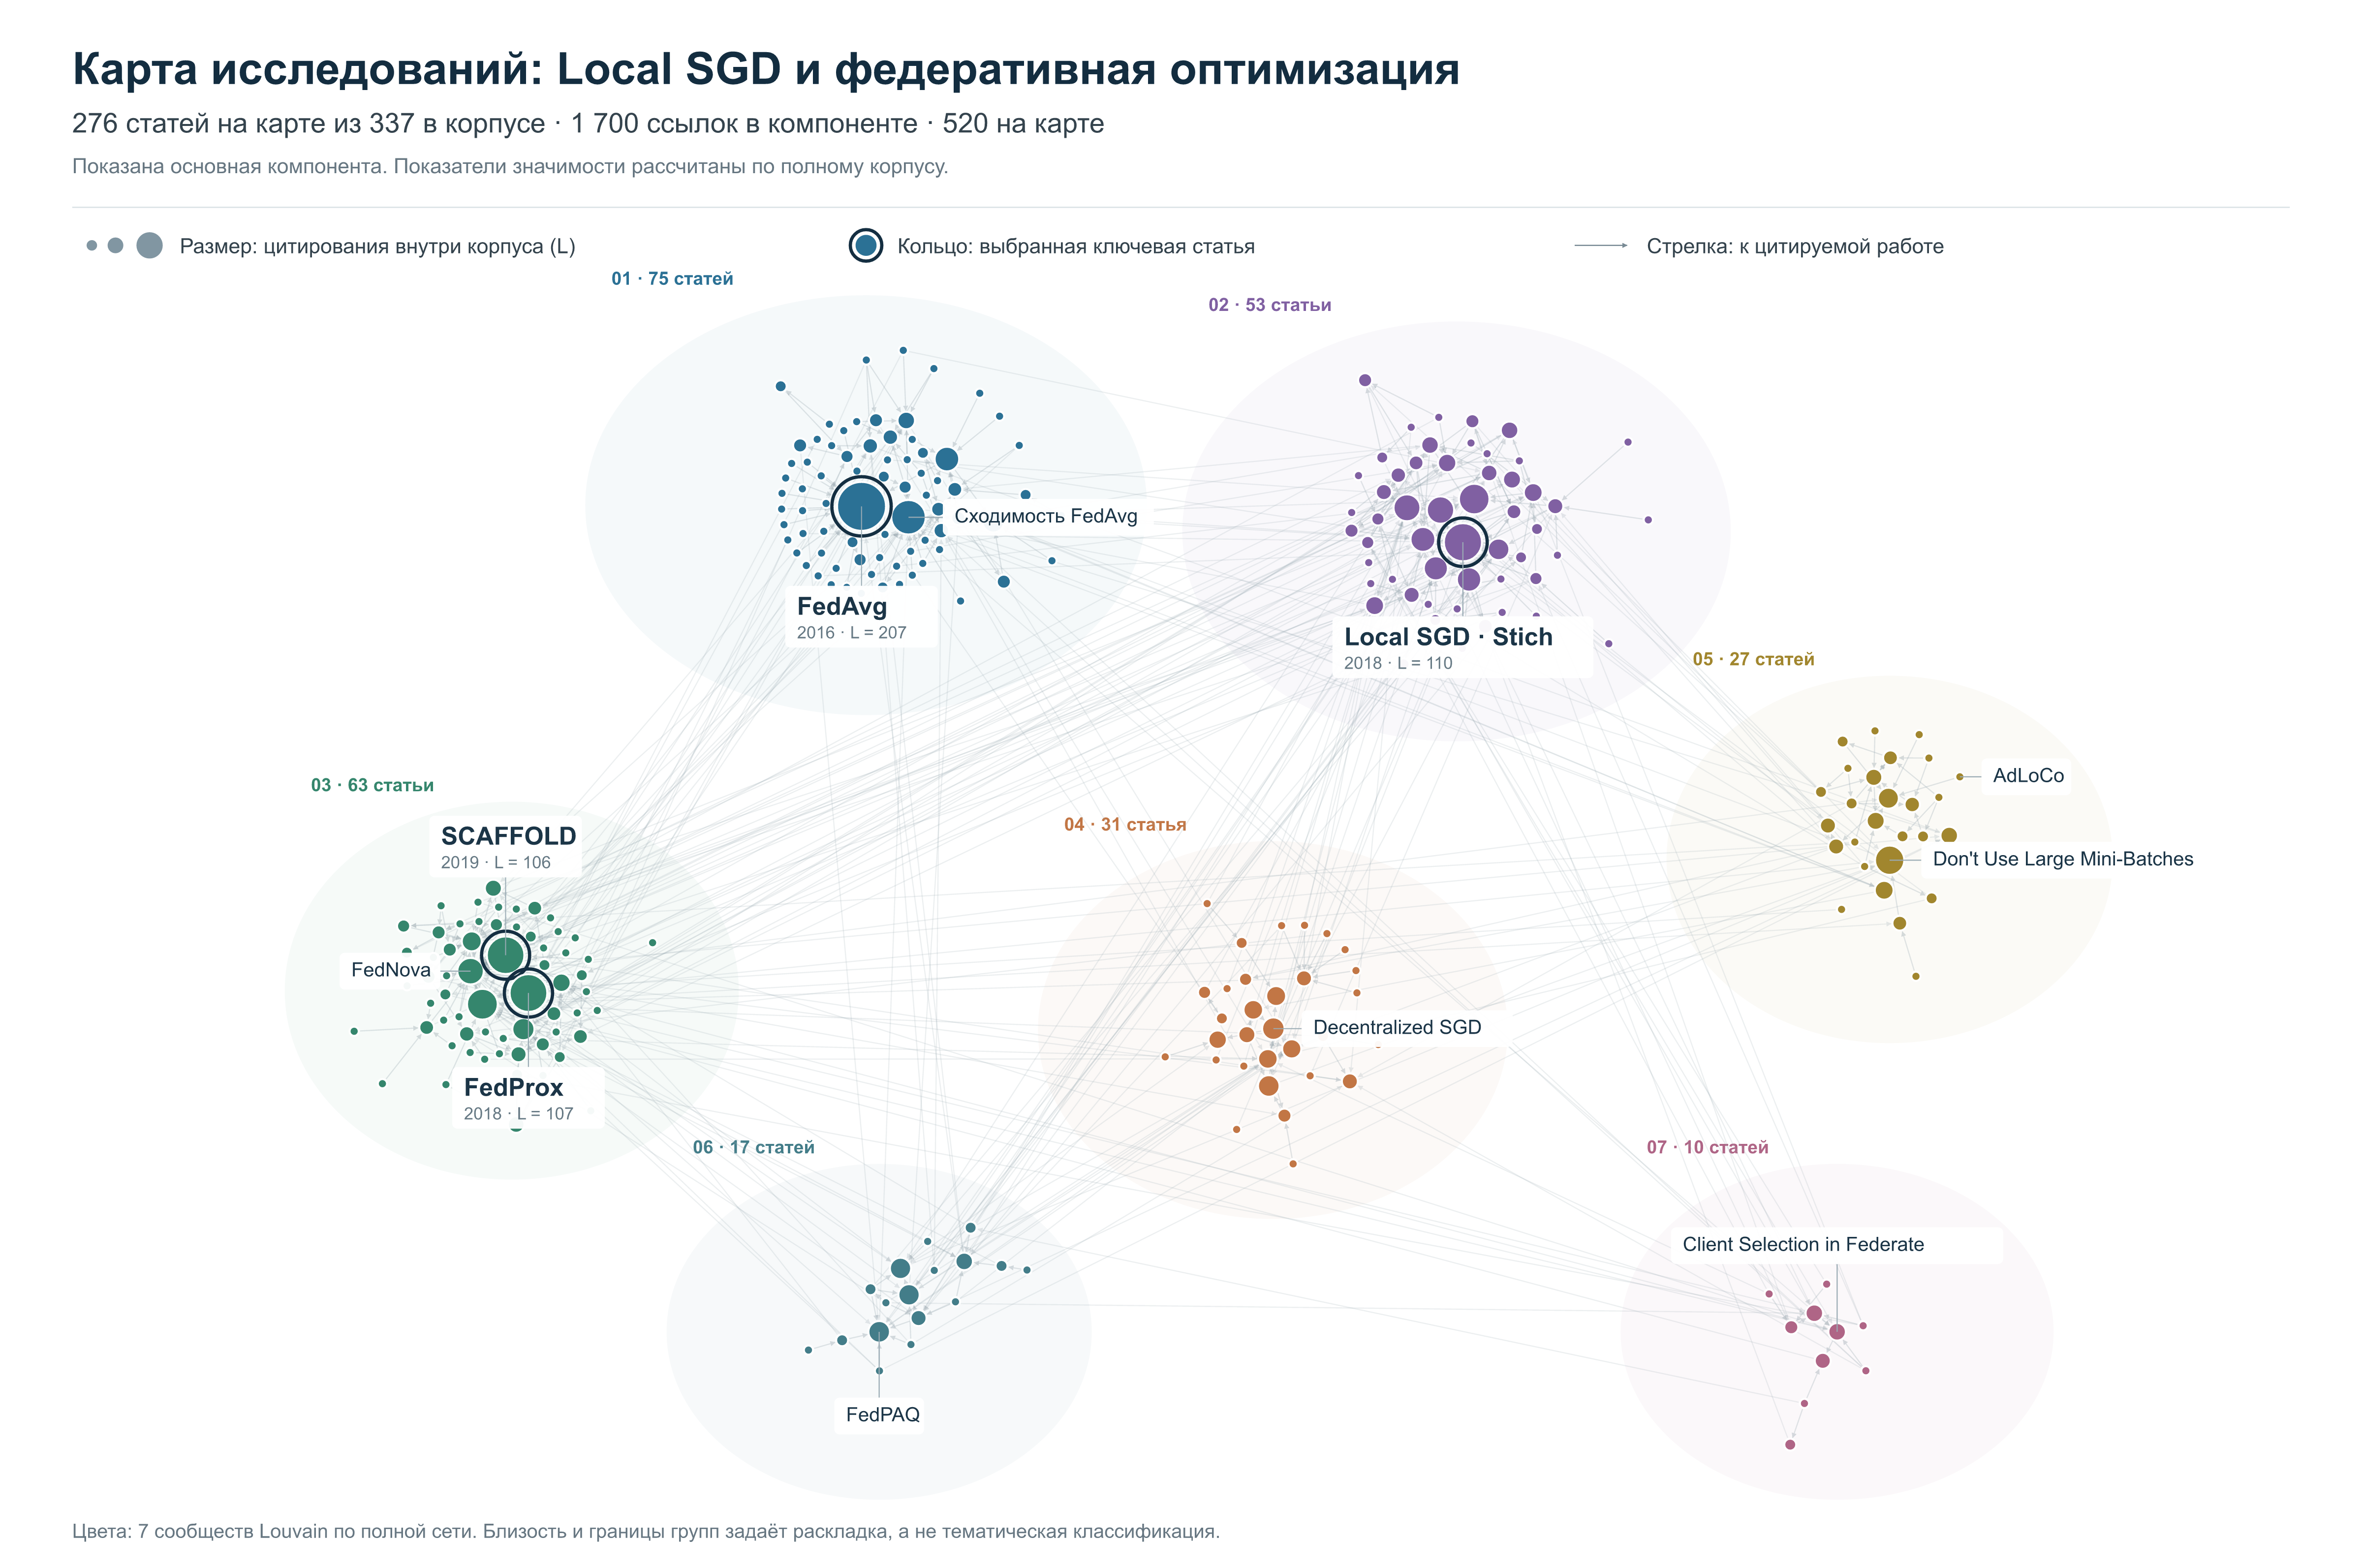

In [28]:
png = resvg_py.svg_to_bytes(svg_string=svg, width=4800, background="white")
(results_dir / "Граф — 337 статей.png").write_bytes(png)
display(Image(data=png, width=1100))

## 5. Изменения по годам

Для каждого года считаю ссылки из статей, опубликованных именно в этом году.
Затем сравниваю порядок одних и тех же работ в соседние годы. На границе топа включаю все статьи с одинаковым числом ссылок.

In [29]:
def gini(values):
    ordered = sorted(values)
    total = sum(ordered)
    n = len(ordered)
    if not total or not n:
        return None
    return sum((2 * j - n - 1) * v for j, v in enumerate(ordered, 1)) / (n * total)


def average_ranks(values):
    positions = {}
    for i, v in enumerate(sorted(values), 1):
        positions.setdefault(v, []).append(i)
    return [statistics.mean(positions[v]) for v in values]


def spearman(x, y):
    x = average_ranks(x)
    y = average_ranks(y)
    mx = statistics.mean(x)
    my = statistics.mean(y)
    cov = sum((a - mx) * (b - my) for a, b in zip(x, y))
    var = math.sqrt(sum((a - mx) ** 2 for a in x) * sum((b - my) ** 2 for b in y))
    return cov / var if var else None


def top_set(counts, k):
    if len(counts) < k:
        return set()
    cutoff = sorted(counts.values(), reverse=True)[k - 1]
    return {i for i, c in counts.items() if c >= cutoff}

In [30]:
years = list(range(2020, 2026))
year_counts = {
    y: Counter(v for u, v in edges if int(papers[u]["date"][:4]) == y) for y in years
}
annual, transitions = ([], [])
for year, count in year_counts.items():
    eligible = {i for i, p in papers.items() if int(p["date"][:4]) <= year}
    leaders = sorted(i for i, value in count.items() if value == max(count.values()))
    annual.append(
        dict(
            year=year,
            gini_cited=gini(count.values()),
            gini_all=gini([count[i] for i in eligible]),
            citations=sum(count.values()),
            leaders="|".join(leaders),
        )
    )
    if year == 2025:
        continue
    for k in [5, 10, 50]:
        if len(count) < k:
            continue
        focal = sorted(top_set(count, k))
        later = top_set(year_counts[year + 1], k)
        transitions.append(
            dict(
                year=year,
                k=k,
                size=len(focal),
                rho=spearman(
                    [count[i] for i in focal], [year_counts[year + 1][i] for i in focal]
                ),
                retention=len(set(focal) & later) / len(focal) if later else np.nan,
            )
        )
annual_df = pd.DataFrame(annual)
transitions_df = pd.DataFrame(transitions)
annual_df.to_csv(results_dir / "annual.csv", index=False)
transitions_df.to_csv(results_dir / "transitions.csv", index=False)
display(
    annual_df.assign(
        leader=annual_df["leaders"].map(
            lambda ids: ", ".join(
                papers[i]["key"] or papers[i]["title"] for i in ids.split("|")
            )
        )
    )
    .drop(columns="leaders")
    .round(3)
)
display(transitions_df[transitions_df["k"].isin([10, 50])].round(3))

,year,gini_cited,gini_all,citations,leader
0,2020,0.537,0.680,271,FedAvg
1,2021,0.510,0.764,333,FedAvg
2,2022,0.469,0.782,156,FedAvg
3,2023,0.564,0.826,402,FedAvg
4,2024,0.471,0.851,193,FedAvg
5,2025,0.544,0.905,252,FedAvg


,year,k,size,rho,retention
1,2020,10,11,0.904,0.818
3,2021,10,12,0.879,0.667
4,2021,50,53,0.625,0.698
6,2022,10,10,0.855,0.900
7,2022,50,57,0.665,0.754
9,2023,10,12,0.723,0.833
10,2023,50,57,0.636,0.702
12,2024,10,13,0.779,0.615
13,2024,50,69,0.638,0.565


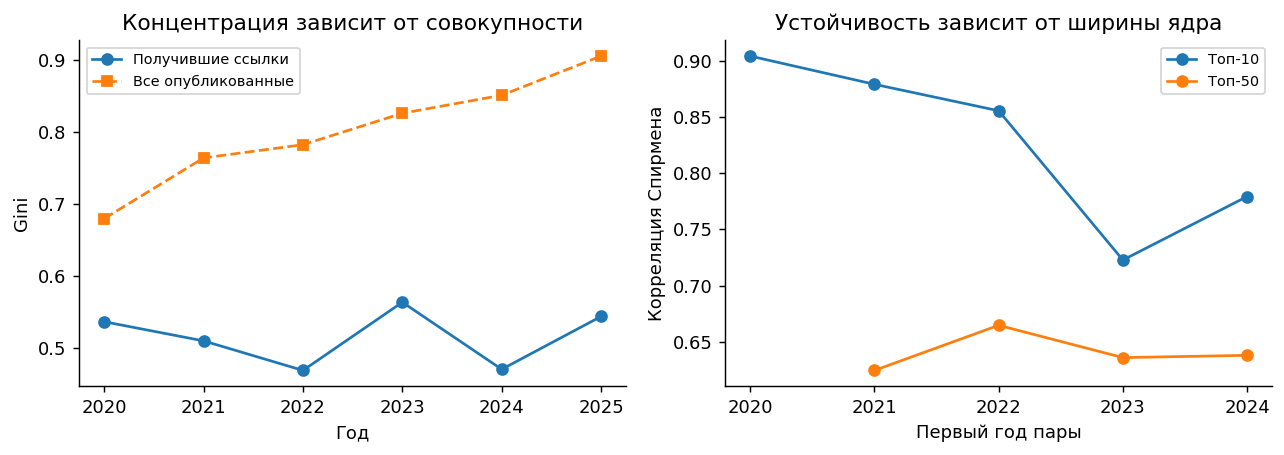

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(annual_df.year, annual_df.gini_cited, "o-", label="Получившие ссылки")
axes[0].plot(annual_df.year, annual_df.gini_all, "s--", label="Все опубликованные")
axes[0].set(xlabel="Год", ylabel="Gini", title="Концентрация зависит от совокупности")
axes[0].legend(fontsize=8)
axes[0].set_xticks(years)
for k, group in transitions_df[transitions_df["k"].isin([10, 50])].groupby("k"):
    axes[1].plot(group.year, group.rho, "o-", label=f"Топ-{k}")
axes[1].set(
    xlabel="Первый год пары",
    ylabel="Корреляция Спирмена",
    title="Устойчивость зависит от ширины ядра",
)
axes[1].legend(fontsize=8)
axes[1].set_xticks(years[:-1])
fig.tight_layout()
fig.savefig(results_dir / "annual_analysis.png", dpi=200, bbox_inches="tight")
plt.show()

По обычному и дробному подсчёту получилась одна и та же четвёрка: FedAvg, Local SGD у Stich, FedProx и SCAFFOLD. FedProx и Stich поменялись местами.

FedAvg остаётся лидером в 2020–2025 годах. Топ-10 устойчивее, чем более широкий круг из 50 работ. Это результат для нашего корпуса; напрямую сравнивать его с другими областями я не стал.